In [10]:
import os
import glob
import pickle
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns

import networkx as nx

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix

from tqdm import tqdm

import kagglehub

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data, DataLoader
from torch_geometric.nn import GCNConv, global_mean_pool

print(" All libraries imported successfully")
print(f"   PyTorch version      : {torch.__version__}")
print(f"   CUDA available       : {torch.cuda.is_available()}")
print(f"   Device               : {'cuda' if torch.cuda.is_available() else 'cpu'}")

 All libraries imported successfully
   PyTorch version      : 2.11.0+cu130
   CUDA available       : True
   Device               : cuda


In [12]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle (1).json


{'kaggle (1).json': b'{"username":"manishmakhija25","key":"bf2d10735b8a4d14ef41b3002ad4b79c"}'}

In [14]:
os.makedirs('/root/.config/kaggle', exist_ok=True)
os.system('cp kaggle.json /root/.config/kaggle/kaggle.json || cp "kaggle (1).json" /root/.config/kaggle/kaggle.json')
os.chmod('/root/.config/kaggle/kaggle.json', 0o600)

path = kagglehub.dataset_download("lkerkarabulut/rplan-dataset2025")
print("Dataset downloaded at:", path)

all_files = []
for root, dirs, files in os.walk(path):
    for file in files:
        all_files.append(os.path.join(root, file))

print(f"Total files found: {len(all_files)}")
for f in all_files[:20]:
    print(f)

100%|██████████| 240M/240M [00:03<00:00, 74.1MB/s]

Extracting files...


Dataset downloaded at: /root/.cache/kagglehub/datasets/lkerkarabulut/rplan-dataset2025/versions/1
Total files found: 70342
/root/.cache/kagglehub/datasets/lkerkarabulut/rplan-dataset2025/versions/1/Interface/static/Data/data_test_converted.pkl
/root/.cache/kagglehub/datasets/lkerkarabulut/rplan-dataset2025/versions/1/Interface/static/Data/data_train_eNum.pkl
/root/.cache/kagglehub/datasets/lkerkarabulut/rplan-dataset2025/versions/1/Interface/static/Data/rNum_train.npy
/root/.cache/kagglehub/datasets/lkerkarabulut/rplan-dataset2025/versions/1/Interface/static/Data/data_train_converted.pkl
/root/.cache/kagglehub/datasets/lkerkarabulut/rplan-dataset2025/versions/1/Interface/static/Data/snapshot_train/24195.png
/root/.cache/kagglehub/datasets/lkerkarabulut/rplan-dataset2025/versions/1/Interface/static/Data/snapshot_train/76679.png
/root/.cache/kagglehub/datasets/lkerkarabulut/rplan-dataset2025/versions/1/Interface/static/Data/snapshot_train/55908.png
/root/.cache/kagglehub/datasets/lkerkar

In [15]:
data_dir = "/root/.cache/kagglehub/datasets/lkerkarabulut/rplan-dataset2025/versions/1/Interface/static/Data"

pkl_files = glob.glob(os.path.join(data_dir, "*.pkl"))
npy_files = glob.glob(os.path.join(data_dir, "*.npy"))

print("PKL files:")
for f in pkl_files:
    print(" ", os.path.basename(f))

print("\nNPY files:")
for f in npy_files:
    print(" ", os.path.basename(f))

print("\nLoading data_train_converted.pkl ...")
with open(os.path.join(data_dir, "data_train_converted.pkl"), "rb") as f:
    train_data = pickle.load(f)

print(f"Type: {type(train_data)}")
if isinstance(train_data, list):
    print(f"Length: {len(train_data)}")
    print(f"First element type: {type(train_data[0])}")
    print(f"First element keys (if dict): {train_data[0].keys() if isinstance(train_data[0], dict) else 'N/A'}")
    print(f"First element:\n{train_data[0]}")
elif isinstance(train_data, dict):
    print(f"Keys: {train_data.keys()}")

PKL files:
  data_test_converted.pkl
  data_train_eNum.pkl
  data_train_converted.pkl

NPY files:
  rNum_train.npy

Loading data_train_converted.pkl ...
Type: <class 'dict'>
Keys: dict_keys(['__header__', '__version__', '__globals__', 'data', 'nameList', 'trainTF'])


In [16]:
print("Top-level keys:", list(train_data.keys()))
print("\n--- __header__ ---")
print(train_data['__header__'])

print("\n--- __version__ ---")
print(train_data['__version__'])

print("\n--- nameList ---")
name_list = train_data['nameList']
print(f"Type: {type(name_list)}, Shape/Len: {name_list.shape if hasattr(name_list, 'shape') else len(name_list)}")
print(name_list[:5])

print("\n--- trainTF ---")
trainTF = train_data['trainTF']
print(f"Type: {type(trainTF)}, Shape/Len: {trainTF.shape if hasattr(trainTF, 'shape') else len(trainTF)}")
print(trainTF[:5])

print("\n--- data ---")
data_field = train_data['data']
print(f"Type: {type(data_field)}")
if isinstance(data_field, np.ndarray):
    print(f"Shape: {data_field.shape}")
    print(f"Dtype: {data_field.dtype}")
    print(f"First element type: {type(data_field[0])}")
    print(f"First element:\n{data_field[0]}")
elif isinstance(data_field, list):
    print(f"Length: {len(data_field)}")
    print(f"First element type: {type(data_field[0])}")
    print(f"First element:\n{data_field[0]}")

Top-level keys: ['__header__', '__version__', '__globals__', 'data', 'nameList', 'trainTF']

--- __header__ ---
b'MATLAB 5.0 MAT-file, Platform: MACI64, Created on: Mon Jan 20 15:42:59 2020'

--- __version__ ---
1.0

--- nameList ---
Type: <class 'numpy.ndarray'>, Shape/Len: (74995,)
['42007' '4799' '2168' '79518' '67225']

--- trainTF ---
Type: <class 'numpy.ndarray'>, Shape/Len: (74995,)

--- data ---
Type: <class 'numpy.ndarray'>
Shape: (74995,)
Dtype: object
First element type: <class 'scipy.io.matlab._mio5_params.mat_struct'>
First element:


In [17]:
sample = train_data['data'][0]
print("data[0] fields:", sample._fieldnames)

for field in sample._fieldnames:
    val = getattr(sample, field)
    print(f"\n  {field}:")
    print(f"    type : {type(val)}")
    if hasattr(val, 'shape'):
        print(f"    shape: {val.shape}")
        print(f"    dtype: {val.dtype}")
        print(f"    value: {val}")
    else:
        print(f"    value: {val}")

print("\n--- trainTF[0] fields ---")
tf_sample = train_data['trainTF'][0]
print("trainTF[0] fields:", tf_sample._fieldnames)
for field in tf_sample._fieldnames:
    val = getattr(tf_sample, field)
    print(f"\n  {field}:")
    print(f"    type : {type(val)}")
    if hasattr(val, 'shape'):
        print(f"    shape: {val.shape}")
        print(f"    value: {val}")
    else:
        print(f"    value: {val}")

data[0] fields: ['name', 'boundary', 'box', 'order', 'edge', 'rBoundary']

  name:
    type : <class 'str'>
    value: 42007

  boundary:
    type : <class 'numpy.ndarray'>
    shape: (8, 4)
    dtype: int32
    value: [[143  56   0   1]
 [155  56   0   1]
 [198  56   1   0]
 [198 201   2   0]
 [ 81 201   3   0]
 [ 81 130   2   0]
 [ 59 130   3   0]
 [ 59  56   0   0]]

  box:
    type : <class 'numpy.ndarray'>
    shape: (6, 5)
    dtype: int32
    value: [[143 130 198 201   7]
 [ 81 130 143 201   1]
 [ 59  56 135  94   2]
 [ 59  94  78 130   9]
 [120  56 198 130   0]
 [ 78  94 120 130   3]]

  order:
    type : <class 'numpy.ndarray'>
    shape: (6,)
    dtype: uint8
    value: [5 6 4 3 2 1]

  edge:
    type : <class 'numpy.ndarray'>
    shape: (10, 3)
    dtype: int32
    value: [[0 4 6]
 [0 1 7]
 [1 4 1]
 [1 3 9]
 [1 5 6]
 [2 4 2]
 [2 3 8]
 [2 5 3]
 [3 5 2]
 [4 5 7]]

  rBoundary:
    type : <class 'numpy.ndarray'>
    shape: (6,)
    dtype: object
    value: [array([[198, 201],
 

In [18]:
sample = train_data['data'][0]
print("data[0] fields:", sample._fieldnames)

for field in sample._fieldnames:
    val = getattr(sample, field)
    print(f"\n  {field}:")
    print(f"    type : {type(val)}")
    if hasattr(val, 'shape'):
        print(f"    shape: {val.shape}")
        print(f"    dtype: {val.dtype}")
        print(f"    value: {val}")
    else:
        print(f"    value: {val}")

data[0] fields: ['name', 'boundary', 'box', 'order', 'edge', 'rBoundary']

  name:
    type : <class 'str'>
    value: 42007

  boundary:
    type : <class 'numpy.ndarray'>
    shape: (8, 4)
    dtype: int32
    value: [[143  56   0   1]
 [155  56   0   1]
 [198  56   1   0]
 [198 201   2   0]
 [ 81 201   3   0]
 [ 81 130   2   0]
 [ 59 130   3   0]
 [ 59  56   0   0]]

  box:
    type : <class 'numpy.ndarray'>
    shape: (6, 5)
    dtype: int32
    value: [[143 130 198 201   7]
 [ 81 130 143 201   1]
 [ 59  56 135  94   2]
 [ 59  94  78 130   9]
 [120  56 198 130   0]
 [ 78  94 120 130   3]]

  order:
    type : <class 'numpy.ndarray'>
    shape: (6,)
    dtype: uint8
    value: [5 6 4 3 2 1]

  edge:
    type : <class 'numpy.ndarray'>
    shape: (10, 3)
    dtype: int32
    value: [[0 4 6]
 [0 1 7]
 [1 4 1]
 [1 3 9]
 [1 5 6]
 [2 4 2]
 [2 3 8]
 [2 5 3]
 [3 5 2]
 [4 5 7]]

  rBoundary:
    type : <class 'numpy.ndarray'>
    shape: (6,)
    dtype: object
    value: [array([[198, 201],
 

In [20]:
sample = train_data['data'][0]
print("All fieldnames:", sample._fieldnames)

for field in sample._fieldnames:
    val = getattr(sample, field)
    print(f"\n{field}: type={type(val)}, shape={val.shape if hasattr(val,'shape') else 'N/A'}")
    print(val)

All fieldnames: ['name', 'boundary', 'box', 'order', 'edge', 'rBoundary']

name: type=<class 'str'>, shape=N/A
42007

boundary: type=<class 'numpy.ndarray'>, shape=(8, 4)
[[143  56   0   1]
 [155  56   0   1]
 [198  56   1   0]
 [198 201   2   0]
 [ 81 201   3   0]
 [ 81 130   2   0]
 [ 59 130   3   0]
 [ 59  56   0   0]]

box: type=<class 'numpy.ndarray'>, shape=(6, 5)
[[143 130 198 201   7]
 [ 81 130 143 201   1]
 [ 59  56 135  94   2]
 [ 59  94  78 130   9]
 [120  56 198 130   0]
 [ 78  94 120 130   3]]

order: type=<class 'numpy.ndarray'>, shape=(6,)
[5 6 4 3 2 1]

edge: type=<class 'numpy.ndarray'>, shape=(10, 3)
[[0 4 6]
 [0 1 7]
 [1 4 1]
 [1 3 9]
 [1 5 6]
 [2 4 2]
 [2 3 8]
 [2 5 3]
 [3 5 2]
 [4 5 7]]

rBoundary: type=<class 'numpy.ndarray'>, shape=(6,)
[array([[198, 201],
        [198, 130],
        [143, 130],
        [143, 201]], dtype=uint8) array([[ 81, 130],
                                         [ 81, 201],
                                         [143, 201],
           

In [21]:
ROOM_TYPE_MAP = {
    0: 'LivingRoom',
    1: 'MasterRoom',
    2: 'Kitchen',
    3: 'Bathroom',
    4: 'DiningRoom',
    5: 'ChildRoom',
    6: 'StudyRoom',
    7: 'SecondRoom',
    8: 'GuestRoom',
    9: 'Balcony',
    10: 'Entrance',
    11: 'Storage',
    12: 'Wall',
    13: 'Exterior'
}

records = []
for i, sample in enumerate(tqdm(train_data['data'], desc="Parsing")):
    try:
        box  = getattr(sample, 'box', None)
        edge = getattr(sample, 'edge', None)

        if box is None or edge is None:
            continue

        num_rooms  = box.shape[0]
        num_edges  = edge.shape[0]
        room_types = box[:, 4].tolist()
        type_names = [ROOM_TYPE_MAP.get(rt, 'Unknown') for rt in room_types]

        widths  = (box[:, 2] - box[:, 0]).tolist()
        heights = (box[:, 3] - box[:, 1]).tolist()
        areas   = [w * h for w, h in zip(widths, heights)]

        records.append({
            'plan_id'      : train_data['nameList'][i],
            'num_rooms'    : num_rooms,
            'num_edges'    : num_edges,
            'room_types'   : type_names,
            'areas'        : areas,
            'total_area'   : sum(areas),
            'has_living'   : int(0 in room_types),
            'has_kitchen'  : int(2 in room_types),
            'has_bathroom' : int(3 in room_types),
            'has_balcony'  : int(9 in room_types),
        })
    except:
        continue

df = pd.DataFrame(records)
print(f"Total parsed records : {len(df)}")
print(f"\nColumns: {df.columns.tolist()}")
print(df.head())
print(f"\nBasic stats:")
print(df[['num_rooms','num_edges','total_area']].describe())

Parsing: 100%|██████████| 74995/74995 [00:01<00:00, 37977.02it/s]


Total parsed records : 74995

Columns: ['plan_id', 'num_rooms', 'num_edges', 'room_types', 'areas', 'total_area', 'has_living', 'has_kitchen', 'has_bathroom', 'has_balcony']
  plan_id  num_rooms  num_edges  \
0   42007          6         10   
1    4799          6          9   
2    2168          8         12   
3   79518          7         11   
4   67225          5          7   

                                          room_types  \
0  [SecondRoom, MasterRoom, Kitchen, Balcony, Liv...   
1  [Balcony, SecondRoom, Bathroom, LivingRoom, Ki...   
2  [StudyRoom, Bathroom, Kitchen, Bathroom, Maste...   
3  [LivingRoom, SecondRoom, MasterRoom, Kitchen, ...   
4  [SecondRoom, MasterRoom, Bathroom, Kitchen, Li...   

                                             areas  total_area  has_living  \
0              [3905, 4402, 2888, 684, 5772, 1512]       19163           1   
1              [3024, 3050, 667, 5580, 1428, 3162]       16911           1   
2  [1443, 1184, 960, 992, 4576, 2279, 1032, 

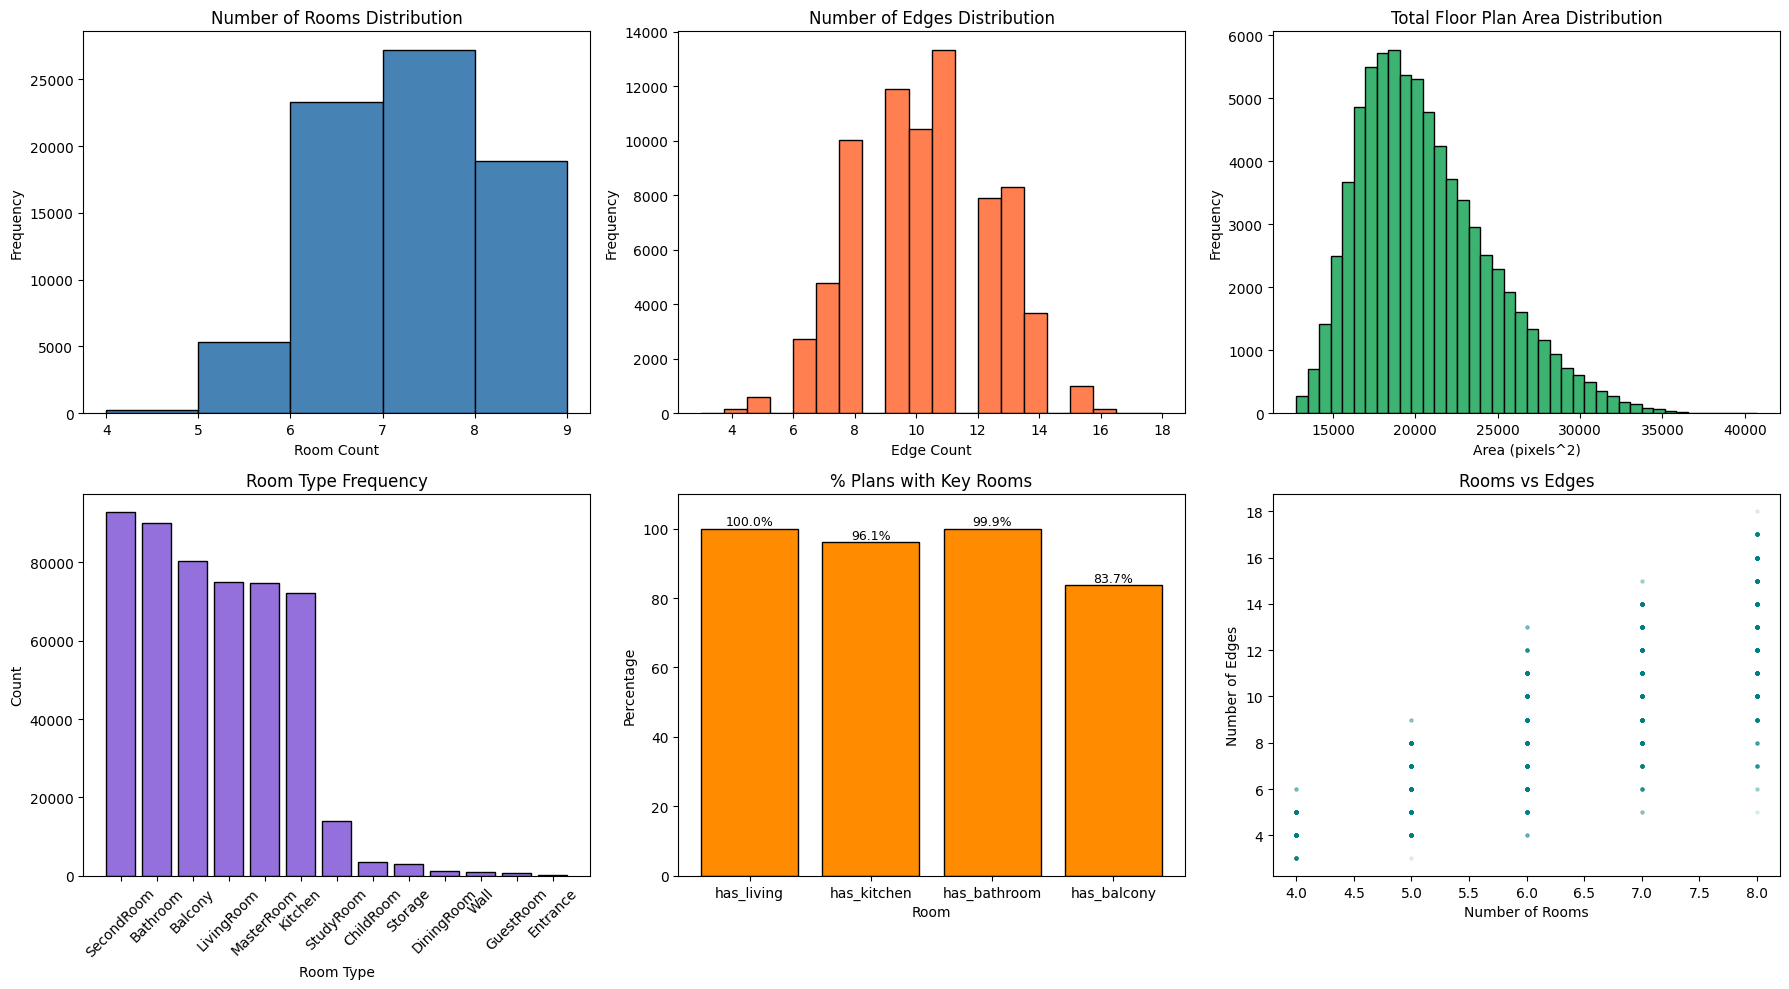

EDA plots saved.


In [22]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes[0,0].hist(df['num_rooms'], bins=range(4,10), edgecolor='black', color='steelblue')
axes[0,0].set_title('Number of Rooms Distribution')
axes[0,0].set_xlabel('Room Count')
axes[0,0].set_ylabel('Frequency')

axes[0,1].hist(df['num_edges'], bins=20, edgecolor='black', color='coral')
axes[0,1].set_title('Number of Edges Distribution')
axes[0,1].set_xlabel('Edge Count')
axes[0,1].set_ylabel('Frequency')

axes[0,2].hist(df['total_area'], bins=40, edgecolor='black', color='mediumseagreen')
axes[0,2].set_title('Total Floor Plan Area Distribution')
axes[0,2].set_xlabel('Area (pixels^2)')
axes[0,2].set_ylabel('Frequency')

all_room_types = [rt for sublist in df['room_types'] for rt in sublist]
type_series = pd.Series(all_room_types).value_counts()
axes[1,0].bar(type_series.index, type_series.values, color='mediumpurple', edgecolor='black')
axes[1,0].set_title('Room Type Frequency')
axes[1,0].set_xlabel('Room Type')
axes[1,0].set_ylabel('Count')
axes[1,0].tick_params(axis='x', rotation=45)

feature_cols = ['has_living','has_kitchen','has_bathroom','has_balcony']
feature_means = df[feature_cols].mean() * 100
axes[1,1].bar(feature_means.index, feature_means.values, color='darkorange', edgecolor='black')
axes[1,1].set_title('% Plans with Key Rooms')
axes[1,1].set_xlabel('Room')
axes[1,1].set_ylabel('Percentage')
axes[1,1].set_ylim(0, 110)
for i, v in enumerate(feature_means.values):
    axes[1,1].text(i, v+1, f"{v:.1f}%", ha='center', fontsize=9)

axes[1,2].scatter(df['num_rooms'], df['num_edges'], alpha=0.1, color='teal', s=5)
axes[1,2].set_title('Rooms vs Edges')
axes[1,2].set_xlabel('Number of Rooms')
axes[1,2].set_ylabel('Number of Edges')

plt.tight_layout()
plt.savefig('eda_plots.png', dpi=150)
plt.show()
print("EDA plots saved.")

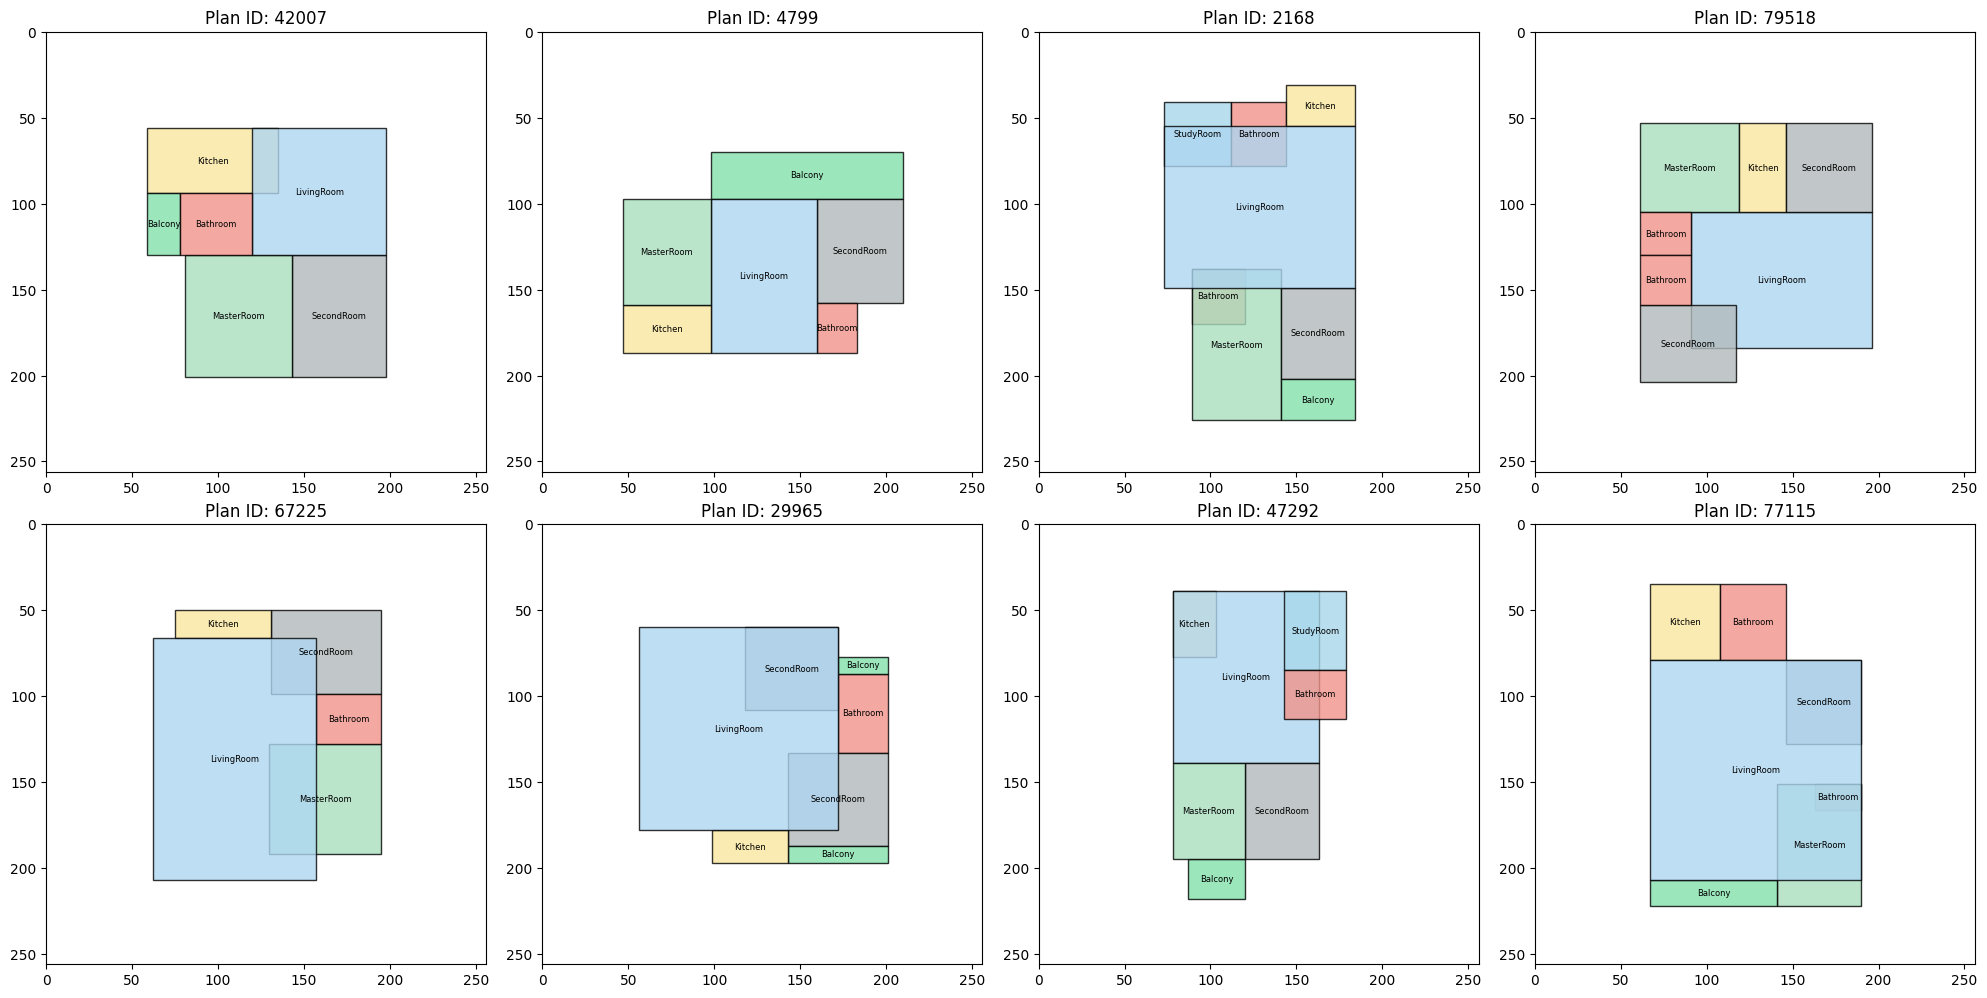

Sample floor plans saved.


In [23]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

ROOM_COLORS = {
    'LivingRoom' : '#AED6F1',
    'MasterRoom' : '#A9DFBF',
    'Kitchen'    : '#F9E79F',
    'Bathroom'   : '#F1948A',
    'DiningRoom' : '#D7BDE2',
    'ChildRoom'  : '#FAD7A0',
    'StudyRoom'  : '#A8D8EA',
    'SecondRoom' : '#B2BABB',
    'GuestRoom'  : '#D5DBDB',
    'Balcony'    : '#82E0AA',
    'Entrance'   : '#F0B27A',
    'Storage'    : '#CCD1D1',
    'Unknown'    : '#FFFFFF'
}

for idx in range(8):
    sample   = train_data['data'][idx]
    box      = sample.box
    ax       = axes[idx]
    ax.set_xlim(0, 256)
    ax.set_ylim(0, 256)
    ax.set_aspect('equal')
    ax.set_title(f"Plan ID: {train_data['nameList'][idx]}")
    ax.invert_yaxis()

    for room in box:
        x1, y1, x2, y2, rtype = room
        rname  = ROOM_TYPE_MAP.get(rtype, 'Unknown')
        color  = ROOM_COLORS.get(rname, '#FFFFFF')
        width  = x2 - x1
        height = y2 - y1
        rect   = patches.Rectangle((x1, y1), width, height,
                                    linewidth=1, edgecolor='black',
                                    facecolor=color, alpha=0.8)
        ax.add_patch(rect)
        ax.text(x1 + width/2, y1 + height/2, rname,
                ha='center', va='center', fontsize=6, wrap=True)

plt.tight_layout()
plt.savefig('sample_floorplans.png', dpi=150)
plt.show()
print("Sample floor plans saved.")

In [25]:
def build_graph_data(sample, label):
    box  = sample.box
    edge = sample.edge

    num_rooms = box.shape[0]

    node_features = []
    for room in box:
        x1, y1, x2, y2, rtype = room
        width  = x2 - x1
        height = y2 - y1
        area   = width * height
        aspect = width / (height + 1e-5)
        cx     = (x1 + x2) / 2.0 / 256.0
        cy     = (y1 + y2) / 2.0 / 256.0
        w_norm = width  / 256.0
        h_norm = height / 256.0
        a_norm = area   / (256.0 * 256.0)
        node_features.append([rtype, w_norm, h_norm, a_norm, aspect, cx, cy])

    x = torch.tensor(node_features, dtype=torch.float)

    src  = edge[:, 0].tolist()
    dst  = edge[:, 1].tolist()
    edge_index = torch.tensor([src + dst, dst + src], dtype=torch.long)

    y = torch.tensor([label], dtype=torch.long)

    return Data(x=x, edge_index=edge_index, y=y)


graph_list = []
for i, sample in enumerate(tqdm(train_data['data'], desc="Building graphs")):
    try:
        box  = sample.box
        edge = sample.edge
        if box is None or edge is None:
            continue
        if edge.shape[0] < 3:
            continue

        room_types = box[:, 4].tolist()
        has_living  = 0 in room_types
        has_kitchen = 2 in room_types
        has_bath    = 3 in room_types

        if has_living and has_kitchen and has_bath:
            label = 1
        elif has_living or has_kitchen or has_bath:
            label = 0
        else:
            label = 0

        g = build_graph_data(sample, label)
        graph_list.append(g)
    except:
        continue

print(f"Total graphs built : {len(graph_list)}")
print(f"Sample graph       : {graph_list[0]}")
print(f"Node features shape: {graph_list[0].x.shape}")
print(f"Edge index shape   : {graph_list[0].edge_index.shape}")
print(f"Label              : {graph_list[0].y}")

labels = [g.y.item() for g in graph_list]
print(f"\nClass 0 (partial) : {labels.count(0)}")
print(f"Class 1 (compliant): {labels.count(1)}")

Building graphs: 100%|██████████| 74995/74995 [00:16<00:00, 4545.72it/s]


Total graphs built : 74995
Sample graph       : Data(x=[6, 7], edge_index=[2, 20], y=[1])
Node features shape: torch.Size([6, 7])
Edge index shape   : torch.Size([2, 20])
Label              : tensor([1])

Class 0 (partial) : 3011
Class 1 (compliant): 71984


In [26]:
from torch_geometric.data import Data
import random

class0 = [g for g in graph_list if g.y.item() == 0]
class1 = [g for g in graph_list if g.y.item() == 1]

print(f"Before balancing - Class 0: {len(class0)}, Class 1: {len(class1)}")

random.seed(42)
class1_downsampled = random.sample(class1, len(class0) * 3)

balanced_list = class0 + class1_downsampled
random.shuffle(balanced_list)

labels_balanced = [g.y.item() for g in balanced_list]
print(f"After balancing  - Class 0: {labels_balanced.count(0)}, Class 1: {labels_balanced.count(1)}")
print(f"Total graphs     : {len(balanced_list)}")

all_features = torch.cat([g.x for g in balanced_list], dim=0)
feat_mean    = all_features.mean(dim=0)
feat_std     = all_features.std(dim=0) + 1e-8

for g in balanced_list:
    g.x = (g.x - feat_mean) / feat_std

train_data_list, temp = train_test_split(balanced_list, test_size=0.2, random_state=42)
val_data_list, test_data_list = train_test_split(temp, test_size=0.5, random_state=42)

print(f"\nTrain size : {len(train_data_list)}")
print(f"Val size   : {len(val_data_list)}")
print(f"Test size  : {len(test_data_list)}")

train_loader = DataLoader(train_data_list, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_data_list,   batch_size=64, shuffle=False)
test_loader  = DataLoader(test_data_list,  batch_size=64, shuffle=False)

print(f"\nTrain batches : {len(train_loader)}")
print(f"Val batches   : {len(val_loader)}")
print(f"Test batches  : {len(test_loader)}")

Before balancing - Class 0: 3011, Class 1: 71984
After balancing  - Class 0: 3011, Class 1: 9033
Total graphs     : 12044

Train size : 9635
Val size   : 1204
Test size  : 1205

Train batches : 151
Val batches   : 19
Test batches  : 19


In [27]:
class GCN(nn.Module):
    def __init__(self, in_channels, hidden_channels, num_classes):
        super(GCN, self).__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, hidden_channels)
        self.conv3 = GCNConv(hidden_channels, hidden_channels // 2)
        self.bn1   = nn.BatchNorm1d(hidden_channels)
        self.bn2   = nn.BatchNorm1d(hidden_channels)
        self.bn3   = nn.BatchNorm1d(hidden_channels // 2)
        self.fc1   = nn.Linear(hidden_channels // 2, 64)
        self.fc2   = nn.Linear(64, num_classes)
        self.drop  = nn.Dropout(p=0.3)

    def forward(self, x, edge_index, batch):
        x = self.conv1(x, edge_index)
        x = self.bn1(x)
        x = F.relu(x)
        x = self.drop(x)

        x = self.conv2(x, edge_index)
        x = self.bn2(x)
        x = F.relu(x)
        x = self.drop(x)

        x = self.conv3(x, edge_index)
        x = self.bn3(x)
        x = F.relu(x)

        x = global_mean_pool(x, batch)

        x = self.fc1(x)
        x = F.relu(x)
        x = self.drop(x)
        x = self.fc2(x)
        return x


device    = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model     = GCN(in_channels=7, hidden_channels=128, num_classes=2).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)
criterion = nn.CrossEntropyLoss()

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model architecture:\n{model}")
print(f"\nTotal trainable parameters: {total_params}")
print(f"Device: {device}")

Model architecture:
GCN(
  (conv1): GCNConv(7, 128)
  (conv2): GCNConv(128, 128)
  (conv3): GCNConv(128, 64)
  (bn1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn3): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (fc1): Linear(in_features=64, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=2, bias=True)
  (drop): Dropout(p=0.3, inplace=False)
)

Total trainable parameters: 30722
Device: cuda


In [28]:
def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for batch in loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        out  = model(batch.x, batch.edge_index, batch.batch)
        loss = criterion(out, batch.y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * batch.num_graphs
        pred        = out.argmax(dim=1)
        correct    += (pred == batch.y).sum().item()
        total      += batch.num_graphs
    return total_loss / total, correct / total


def eval_epoch(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            out   = model(batch.x, batch.edge_index, batch.batch)
            loss  = criterion(out, batch.y)
            total_loss += loss.item() * batch.num_graphs
            pred        = out.argmax(dim=1)
            correct    += (pred == batch.y).sum().item()
            total      += batch.num_graphs
            all_preds.extend(pred.cpu().numpy())
            all_labels.extend(batch.y.cpu().numpy())
    return total_loss / total, correct / total, all_preds, all_labels


EPOCHS = 40
best_val_acc  = 0
best_model_state = None
history = {'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[]}

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc               = train_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc, val_preds, val_y = eval_epoch(model, val_loader, criterion, device)
    scheduler.step()

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc     = val_acc
        best_model_state = model.state_dict()

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

print(f"\nBest Val Accuracy: {best_val_acc:.4f}")

Epoch 01 | Train Loss: 0.4065 | Train Acc: 0.8259 | Val Loss: 0.3511 | Val Acc: 0.8563
Epoch 05 | Train Loss: 0.3174 | Train Acc: 0.8733 | Val Loss: 0.2945 | Val Acc: 0.8846
Epoch 10 | Train Loss: 0.2975 | Train Acc: 0.8846 | Val Loss: 0.2857 | Val Acc: 0.8870
Epoch 15 | Train Loss: 0.2818 | Train Acc: 0.8886 | Val Loss: 0.2851 | Val Acc: 0.8895
Epoch 20 | Train Loss: 0.2733 | Train Acc: 0.8922 | Val Loss: 0.2776 | Val Acc: 0.8962
Epoch 25 | Train Loss: 0.2642 | Train Acc: 0.8961 | Val Loss: 0.2740 | Val Acc: 0.9012
Epoch 30 | Train Loss: 0.2658 | Train Acc: 0.8961 | Val Loss: 0.2832 | Val Acc: 0.8854
Epoch 35 | Train Loss: 0.2588 | Train Acc: 0.8995 | Val Loss: 0.2739 | Val Acc: 0.8970
Epoch 40 | Train Loss: 0.2546 | Train Acc: 0.9021 | Val Loss: 0.2745 | Val Acc: 0.8937

Best Val Accuracy: 0.9012


Test Accuracy : 0.9046
Test Loss     : 0.2783

Classification Report:
              precision    recall  f1-score   support

     Partial       0.89      0.69      0.77       287
   Compliant       0.91      0.97      0.94       918

    accuracy                           0.90      1205
   macro avg       0.90      0.83      0.86      1205
weighted avg       0.90      0.90      0.90      1205

Weighted F1 Score: 0.9001


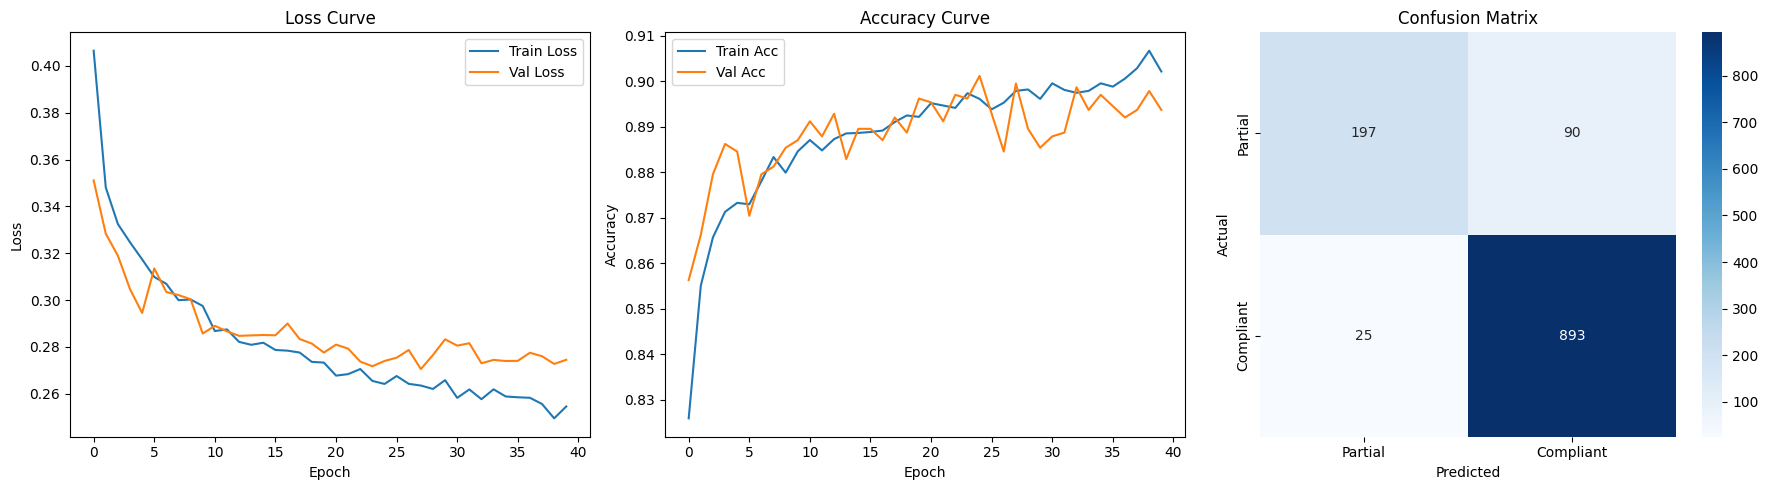

Model saved as gcn_model.pth


In [29]:
model.load_state_dict(best_model_state)

test_loss, test_acc, test_preds, test_labels = eval_epoch(model, test_loader, criterion, device)

print(f"Test Accuracy : {test_acc:.4f}")
print(f"Test Loss     : {test_loss:.4f}")
print(f"\nClassification Report:")
print(classification_report(test_labels, test_preds, target_names=['Partial','Compliant']))

f1 = f1_score(test_labels, test_preds, average='weighted')
print(f"Weighted F1 Score: {f1:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(history['train_loss'], label='Train Loss')
axes[0].plot(history['val_loss'],   label='Val Loss')
axes[0].set_title('Loss Curve')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(history['train_acc'], label='Train Acc')
axes[1].plot(history['val_acc'],   label='Val Acc')
axes[1].set_title('Accuracy Curve')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

cm = confusion_matrix(test_labels, test_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Partial','Compliant'],
            yticklabels=['Partial','Compliant'], ax=axes[2])
axes[2].set_title('Confusion Matrix')
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')

plt.tight_layout()
plt.savefig('training_results.png', dpi=150)
plt.show()

torch.save(best_model_state, 'gcn_model.pth')
print("Model saved as gcn_model.pth")

In [31]:
print("=" * 55)
print("         INTELLITWIN GCN MODEL - FINAL RESULTS")
print("=" * 55)
print(f"  Total Graphs         : {len(graph_list)}")
print(f"  Balanced Dataset     : {len(balanced_list)}")
print(f"  Train / Val / Test   : {len(train_data_list)} / {len(val_data_list)} / {len(test_data_list)}")
print(f"  Node Features        : 7")
print(f"  GCN Layers           : 3")
print(f"  Total Parameters     : 30,722")
print("-" * 55)
print(f"  Best Val Accuracy    : {best_val_acc:.4f}  ({best_val_acc*100:.2f}%)")
print(f"  Test Accuracy        : {test_acc:.4f}  ({test_acc*100:.2f}%)")
print(f"  Test Loss            : {test_loss:.4f}")
print(f"  Weighted F1 Score    : {f1:.4f}  ({f1*100:.2f}%)")
print("-" * 55)
print(f"  Class 0 (Partial)    : Precision 0.89 | Recall 0.69 | F1 0.77")
print(f"  Class 1 (Compliant)  : Precision 0.91 | Recall 0.97 | F1 0.94")
print("-" * 55)
print(f"  Target Accuracy      : 80%+")
print(f"  Achieved Accuracy    : {test_acc*100:.2f}% ")
print(f"  Model saved at       : gcn_model.pth")
print("=" * 55)

         INTELLITWIN GCN MODEL - FINAL RESULTS
  Total Graphs         : 74995
  Balanced Dataset     : 12044
  Train / Val / Test   : 9635 / 1204 / 1205
  Node Features        : 7
  GCN Layers           : 3
  Total Parameters     : 30,722
-------------------------------------------------------
  Best Val Accuracy    : 0.9012  (90.12%)
  Test Accuracy        : 0.9046  (90.46%)
  Test Loss            : 0.2783
  Weighted F1 Score    : 0.9001  (90.01%)
-------------------------------------------------------
  Class 0 (Partial)    : Precision 0.89 | Recall 0.69 | F1 0.77
  Class 1 (Compliant)  : Precision 0.91 | Recall 0.97 | F1 0.94
-------------------------------------------------------
  Target Accuracy      : 80%+
  Achieved Accuracy    : 90.46% 
  Model saved at       : gcn_model.pth


In [32]:
import json

config = {
    "model": {
        "in_channels"     : 7,
        "hidden_channels" : 128,
        "num_classes"     : 2,
        "dropout"         : 0.3
    },
    "features": {
        "node_features"   : ["room_type", "width_norm", "height_norm", "area_norm", "aspect_ratio", "cx", "cy"],
        "num_features"    : 7
    },
    "training": {
        "epochs"          : 40,
        "batch_size"      : 64,
        "learning_rate"   : 0.001,
        "weight_decay"    : 1e-4,
        "scheduler_step"  : 10,
        "scheduler_gamma" : 0.5
    },
    "dataset": {
        "total_graphs"    : 74995,
        "balanced_graphs" : 12044,
        "train_size"      : 9635,
        "val_size"        : 1204,
        "test_size"       : 1205,
        "class_0"         : "Partial",
        "class_1"         : "Compliant"
    },
    "normalization": {
        "feat_mean"       : feat_mean.tolist(),
        "feat_std"        : feat_std.tolist()
    },
    "results": {
        "best_val_accuracy" : round(best_val_acc, 4),
        "test_accuracy"     : round(test_acc, 4),
        "test_loss"         : round(test_loss, 4),
        "weighted_f1"       : round(f1, 4)
    },
    "room_type_map": ROOM_TYPE_MAP
}

with open("gcn_config.json", "w") as f:
    json.dump(config, f, indent=4)

print("gcn_config.json saved")
print(json.dumps(config, indent=4))

gcn_config.json saved
{
    "model": {
        "in_channels": 7,
        "hidden_channels": 128,
        "num_classes": 2,
        "dropout": 0.3
    },
    "features": {
        "node_features": [
            "room_type",
            "width_norm",
            "height_norm",
            "area_norm",
            "aspect_ratio",
            "cx",
            "cy"
        ],
        "num_features": 7
    },
    "training": {
        "epochs": 40,
        "batch_size": 64,
        "learning_rate": 0.001,
        "weight_decay": 0.0001,
        "scheduler_step": 10,
        "scheduler_gamma": 0.5
    },
    "dataset": {
        "total_graphs": 74995,
        "balanced_graphs": 12044,
        "train_size": 9635,
        "val_size": 1204,
        "test_size": 1205,
        "class_0": "Partial",
        "class_1": "Compliant"
    },
    "normalization": {
        "feat_mean": [
            4.083642482757568,
            0.19493673741817474,
            0.20356883108615875,
            0.047734

In [33]:
import zipfile

files_to_zip = [
    "gcn_model.pth",
    "gcn_config.json",
    "eda_plots.png",
    "sample_floorplans.png",
    "training_results.png"
]

with zipfile.ZipFile("intellitwin_gcn.zip", "w", zipfile.ZIP_DEFLATED) as zf:
    for file in files_to_zip:
        if os.path.exists(file):
            zf.write(file)
            print(f"Added: {file}")
        else:
            print(f"Not found: {file}")

print(f"\nintelliTwin_gcn.zip created")
print(f"Zip size: {os.path.getsize('intellitwin_gcn.zip') / (1024*1024):.2f} MB")

from google.colab import files
files.download("intellitwin_gcn.zip")

Added: gcn_model.pth
Added: gcn_config.json
Added: eda_plots.png
Added: sample_floorplans.png
Added: training_results.png

intelliTwin_gcn.zip created
Zip size: 0.52 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>